# Tarea 7:

> Uriel Aguilar Mauricio

1. Cargar Dataset KC1
2. Generar estadísticas descriptivas
3. Analizar todas las métricas que apliquen
para el ejercicio
4. Construir histogramas
5. Comparar defectuosos y no defectuosos

***Importar librerias***

In [76]:
import pandas as pd
import numpy as np
from scipy.io import arff
import matplotlib.pyplot as plt
import seaborn as sns

***Cargar dataset***

In [77]:
data, meta = arff.loadarff("../data/raw/kc1.arff")

df = pd.DataFrame(data)

In [78]:
df.head(2)

,loc,v(g),ev(g),iv(g),n,v,l,d,i,e,...,lOCode,lOComment,lOBlank,locCodeAndComment,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount,defects
0,1.1,1.4,1.4,1.4,1.3,1.3,1.3,1.3,1.3,1.3,...,2.0,2.0,2.0,2.0,1.2,1.2,1.2,1.2,1.4,b'false'
1,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,b'true'


***Preparar los datos***

In [79]:
for columna in df.select_dtypes(include="object").columns:
    df[columna] = df[columna].apply(
        lambda valor: valor.decode("utf-8") if isinstance(valor, (bytes, bytearray)) else valor
    )


df["defects"] = df["defects"].astype(str).str.strip().str.lower()

metricas = df.select_dtypes(include=np.number).columns.tolist()


***Numero de metricas numericas***

In [80]:
len(metricas)

21

***Valores de la variable objetivo***

In [81]:
df["defects"].value_counts(dropna=False)

defects
false    1783
true      326
Name: count, dtype: int64

In [82]:
metricas

['loc',
 'v(g)',
 'ev(g)',
 'iv(g)',
 'n',
 'v',
 'l',
 'd',
 'i',
 'e',
 'b',
 't',
 'lOCode',
 'lOComment',
 'lOBlank',
 'locCodeAndComment',
 'uniq_Op',
 'uniq_Opnd',
 'total_Op',
 'total_Opnd',
 'branchCount']

| Métrica | Descripcion |
|---|---|
| `loc` | Líneas de código |
| `v(g)` | Complejidad ciclomática de McCabe |
| `ev(g)` | Complejidad esencial |
| `iv(g)` | Complejidad de diseño |
| `n` | Total de operadores + operandos de Halstead |
| `v` | Volumen de Halstead |
| `l` | Nivel/longitud relativa del programa |
| `d` | Dificultad de Halstead |
| `i` | Inteligencia/contenido de Halstead |
| `e` | Esfuerzo de Halstead |
| `b` | Estimación de errores de Halstead |
| `t` | Tiempo estimado de Halstead |
| `lOCode` | Líneas de código según Halstead |
| `lOComment` | Líneas de comentarios |
| `lOBlank` | Líneas en blanco |
| `locCodeAndComment` | Líneas de código y comentarios |
| `uniq_Op` | Operadores únicos |
| `uniq_Opnd` | Operandos únicos |
| `total_Op` | Total de operadores |
| `total_Opnd` | Total de operandos |
| `branchCount` | Número de ramas del flujo de control |

***Revisar tipo de datos, valores faltantes, duplicados y valores unicos***

In [83]:
verificar = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "faltantes": df.isna().sum(),
    "porcentaje_faltantes": df.isna().mean() * 100,
    "valores_unicos": df.nunique(dropna=False)
})

In [84]:
verificar

,tipo,faltantes,porcentaje_faltantes,valores_unicos
loc,float64,0,0.0,139
v(g),float64,0,0.0,31
ev(g),float64,0,0.0,21
iv(g),float64,0,0.0,26
n,float64,0,0.0,278
v,float64,0,0.0,729
l,float64,0,0.0,52
d,float64,0,0.0,548
i,float64,0,0.0,893
e,float64,0,0.0,961


In [85]:
df.duplicated().sum()

np.int64(897)

In [86]:
df.isna().sum().sum()

np.int64(0)

No hay valores faltantes, el mayor con valores unicos es volumen de Halsted, existen 897 duplicados y no hay valores vacios

***Ver la distribucion de la variable objtivo***

In [87]:
conteo_clases = df["defects"].value_counts()
porcentaje_clases = df["defects"].value_counts(normalize=True).mul(100)

In [88]:
conteo_clases,porcentaje_clases

(defects
 false    1783
 true      326
 Name: count, dtype: int64,
 defects
 false    84.542437
 true     15.457563
 Name: proportion, dtype: float64)

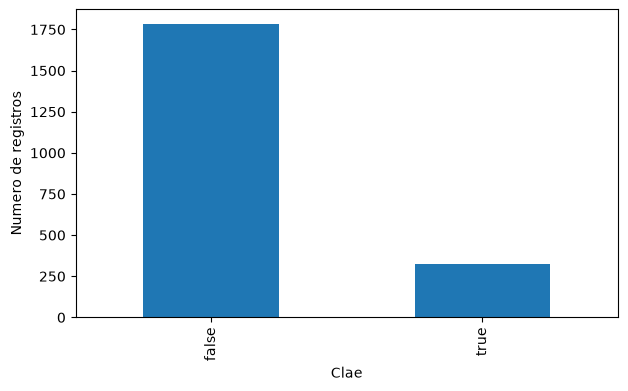

In [89]:
plt.Figure()
conteo_clases.plot(kind="bar", figsize=(7,4))
plt.xlabel("Clae")
plt.ylabel("Numero de registros")
plt.show()

El conjunto de datos esta desbalanceado, ya que la clase false es el que predomina

***Resumen de los 5 números***

In [90]:
df[metricas].describe().T

,count,mean,std,min,25%,50%,75%,max
loc,2109.0,20.372262,29.754442,1.0,3.00,9.00,24.00,288.00
v(g),2109.0,2.838028,3.900763,1.0,1.00,1.00,3.00,45.00
ev(g),2109.0,1.674443,2.200659,1.0,1.00,1.00,1.00,26.00
iv(g),2109.0,2.546420,3.375859,1.0,1.00,1.00,3.00,45.00
n,2109.0,49.829445,83.599874,0.0,4.00,16.00,58.00,1106.00
v,2109.0,258.696719,516.317605,0.0,8.00,57.06,265.93,7918.82
l,2109.0,0.319583,0.317029,0.0,0.08,0.20,0.67,2.00
d,2109.0,6.771242,7.863646,0.0,1.50,3.50,9.20,53.75
i,2109.0,21.240071,21.500367,0.0,5.33,14.40,29.85,193.06
e,2109.0,5242.386240,17444.981211,0.0,12.00,213.97,2276.02,324803.51


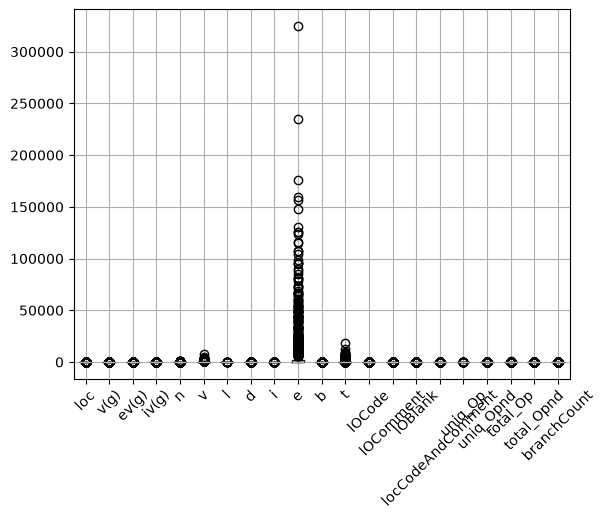

In [91]:
plt.Figure()
df[metricas].boxplot()
plt.xticks(rotation=45)
plt.show()

***Dispersion***

In [92]:
dispersion = pd.DataFrame({
    "std": df[metricas].std(),
    "var": df[metricas].var(),
    "rango": df[metricas].max() - df[metricas].min(),
    "IQR": df[metricas].quantile(0.75) - df[metricas].quantile(0.25),
    "CV": df[metricas].std() / df[metricas].mean().abs().replace(0, np.nan)
})

Variables con mayor Desviacion estandar

In [93]:
dispersion.sort_values("std", ascending=False).head(5)

,std,var,rango,IQR,CV
e,17444.981211,3.043274e+08,324803.51,2264.02,3.327679
t,969.165160,9.392811e+05,18044.64,125.78,3.327662
v,516.317605,2.665839e+05,7918.82,257.93,1.995841
n,83.599874,6.988939e+03,1106.00,54.00,1.677720
total_Op,51.776056,2.680760e+03,678.00,33.00,1.667843


Variables con mayor dispersión

In [94]:
dispersion.sort_values("CV", ascending=False).head(5)

,std,var,rango,IQR,CV
locCodeAndComment,0.704023,4.956480e-01,12.00,0.00,5.302800
e,17444.981211,3.043274e+08,324803.51,2264.02,3.327679
t,969.165160,9.392811e+05,18044.64,125.78,3.327662
lOComment,3.085271,9.518898e+00,44.00,0.00,3.261572
lOBlank,3.856850,1.487529e+01,58.00,2.00,2.191888


e y locCodeAndComment tienen la mayor dispersion

***Metricas con valores  maximos***

In [95]:
df[metricas].max().sort_values(ascending=False)

e                    324803.51
t                     18044.64
v                      7918.82
n                      1106.00
total_Op                678.00
total_Opnd              428.00
loc                     288.00
lOCode                  262.00
i                       193.06
uniq_Opnd               120.00
branchCount              89.00
lOBlank                  58.00
d                        53.75
v(g)                     45.00
iv(g)                    45.00
lOComment                44.00
uniq_Op                  37.00
ev(g)                    26.00
locCodeAndComment        12.00
b                         2.64
l                         2.00
dtype: float64

e es la metrica con el valor maximo numerico mas elevado

***Histograma***

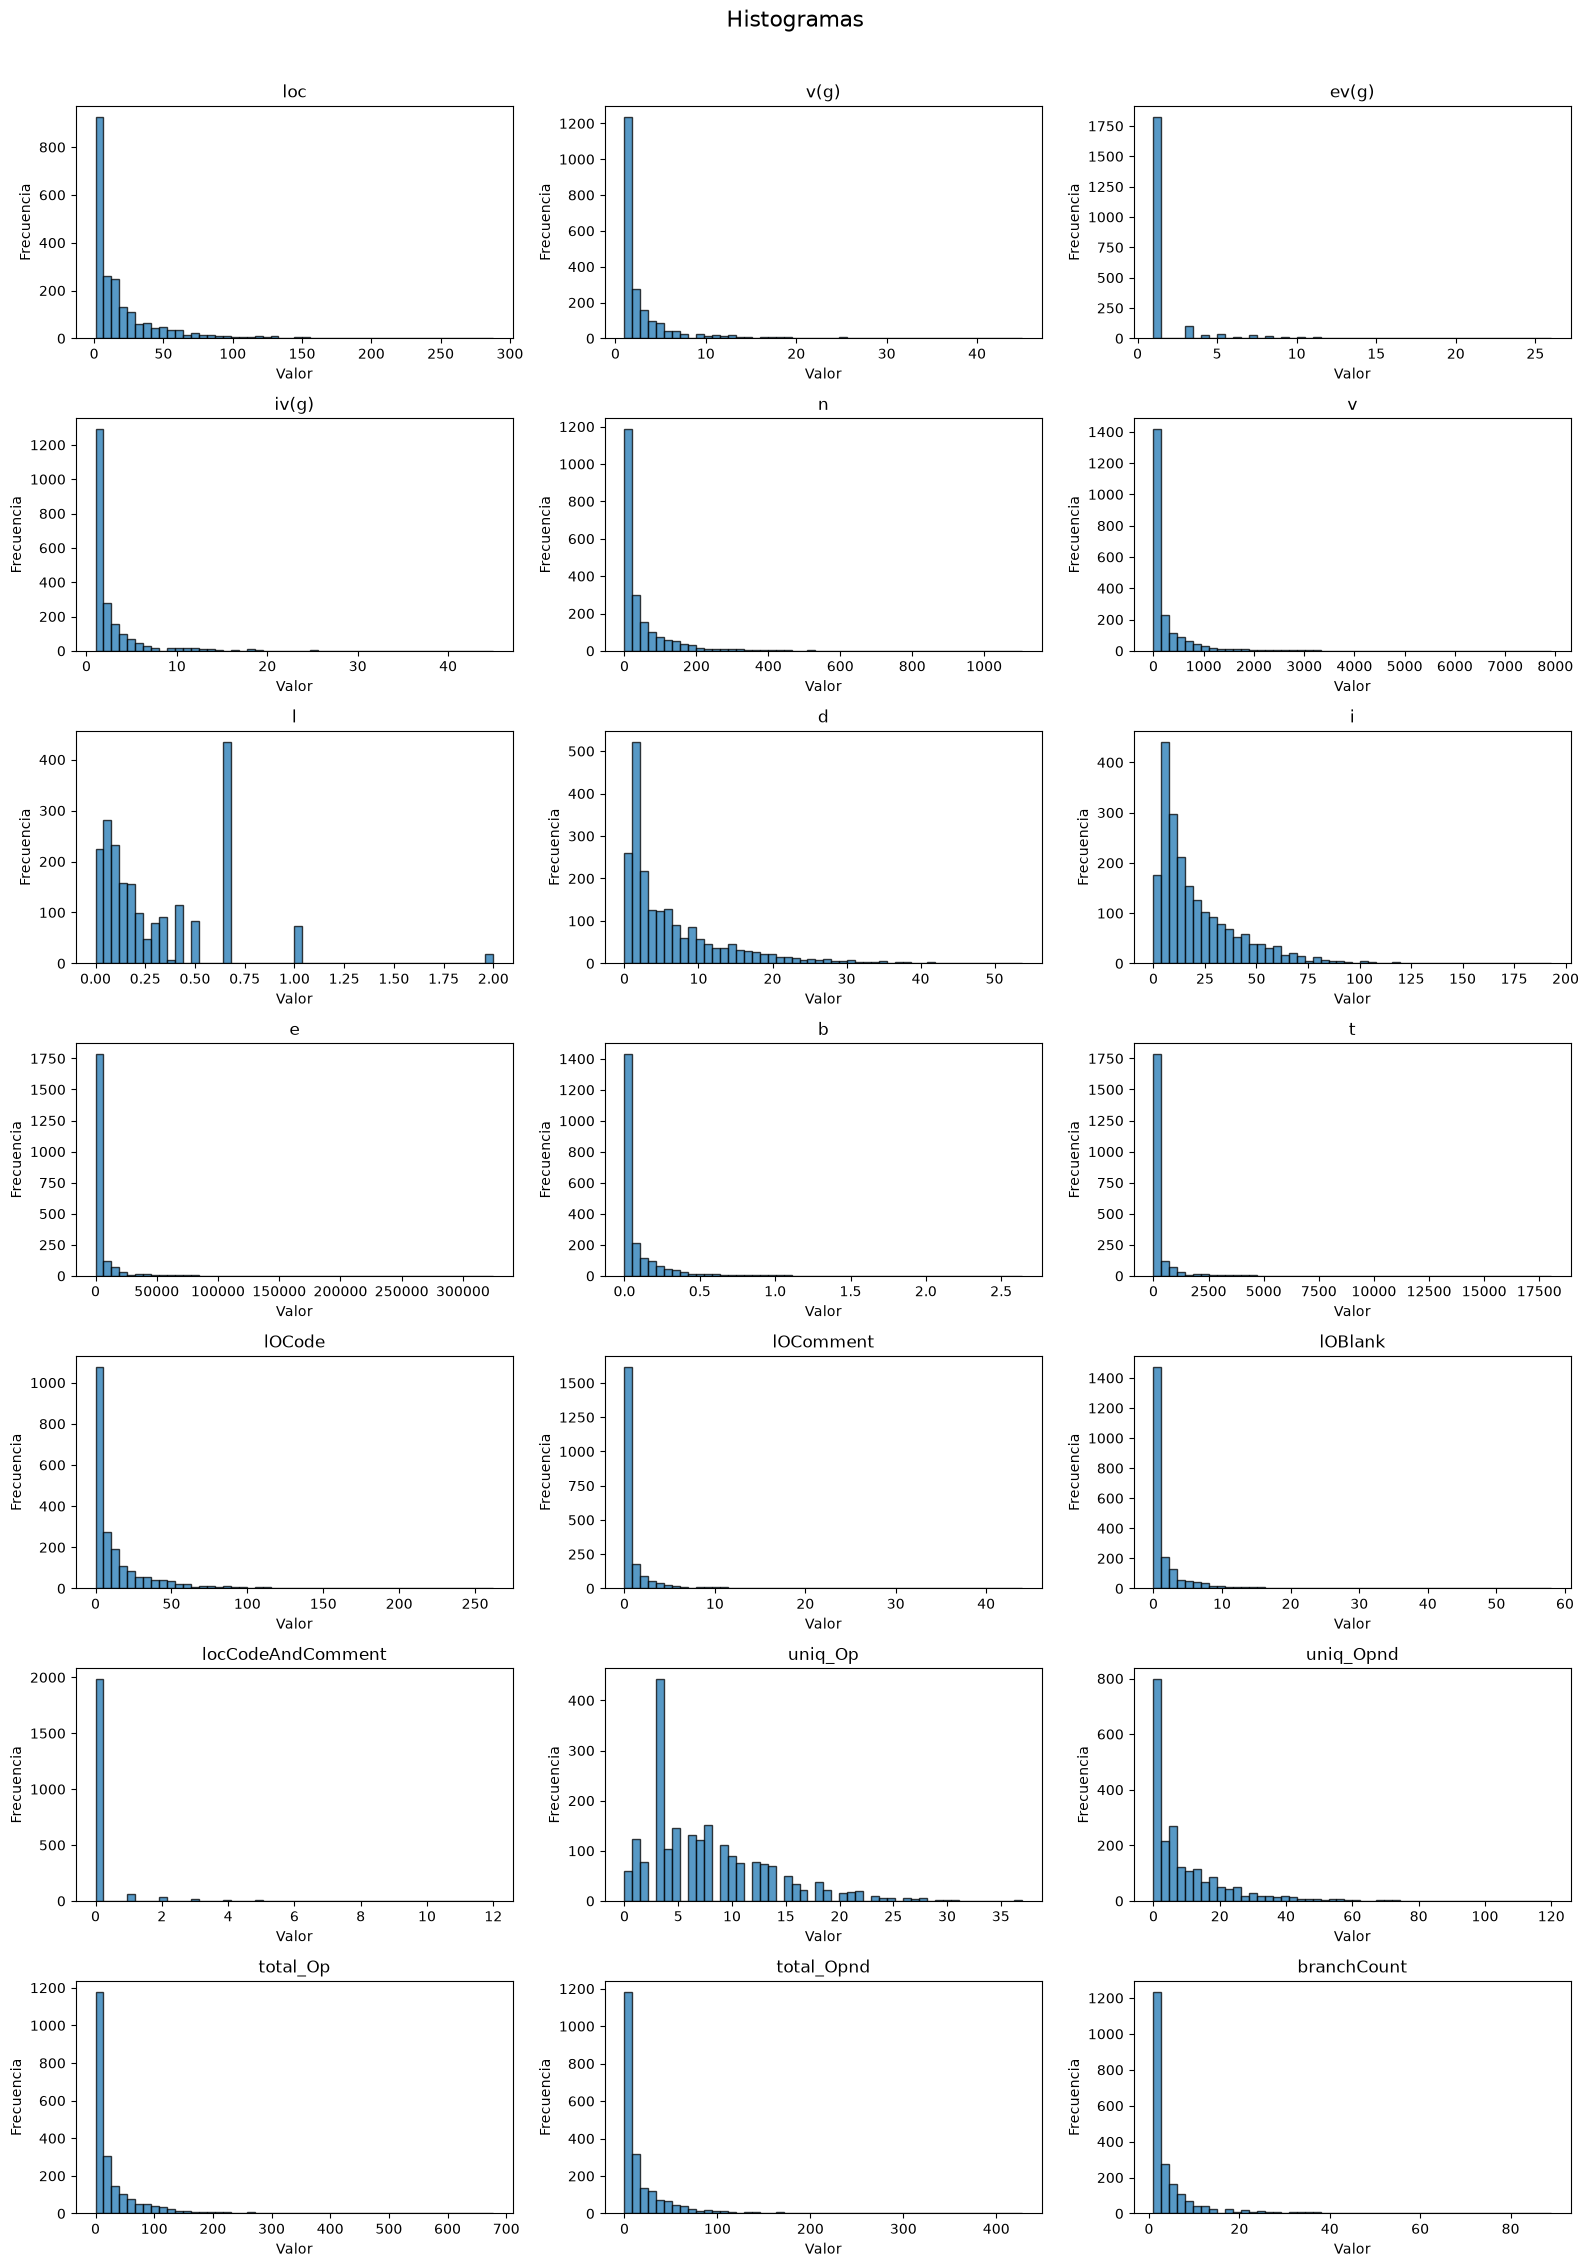

In [96]:
cols = 3
rows = int(np.ceil(len(metricas)/ cols))

fig, axes = plt.subplots(rows, cols, figsize=(16, rows * 3.2))
axes = np.array(axes).reshape(-1)

for ax, metrica in zip(axes, metricas):
    ax.hist(df[metrica].dropna(), bins=50, edgecolor="black", alpha=0.75)
    ax.set_title(metrica)
    ax.set_xlabel("Valor")
    ax.set_ylabel("Frecuencia")
fig.suptitle("Histogramas", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

***Ver metricas con mayor asimetria***

In [97]:
df[metricas].skew().sort_values(ascending=False)

locCodeAndComment    8.789034
t                    7.699120
e                    7.699113
lOComment            6.569980
lOBlank              4.780011
ev(g)                4.632832
v                    4.581499
b                    4.529341
iv(g)                4.018701
branchCount          3.755887
v(g)                 3.737101
total_Opnd           3.716466
total_Op             3.698032
n                    3.697793
lOCode               3.416811
loc                  3.352322
uniq_Opnd            2.387301
d                    2.139364
i                    2.131496
l                    1.793769
uniq_Op              1.140766
dtype: float64

locCodeAndComment, t y e  son los que tiene una cola derecha mas pronunciada

***Correlacion***

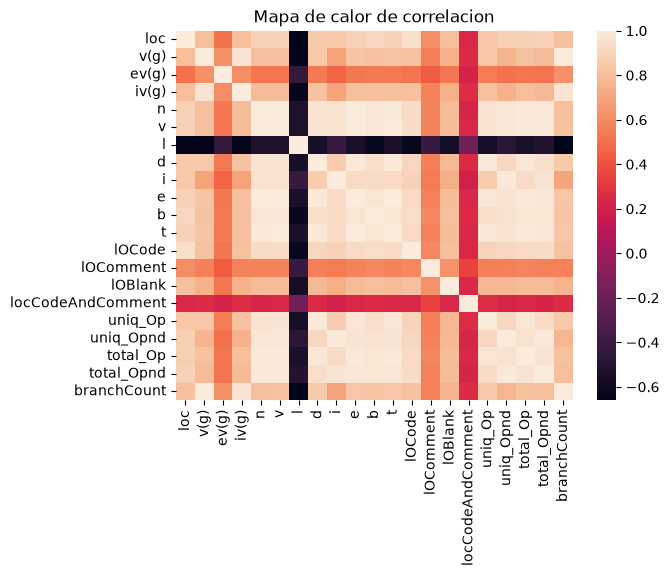

In [98]:
correlation = df[metricas].corr(method='spearman')

sns.heatmap(correlation)
plt.title("Mapa de calor de correlacion")
plt.show()

***Comparar clases***

In [99]:
df.groupby("defects")[metricas].mean().T

defects,false,true
loc,15.940606,44.610429
v(g),2.345149,5.533742
ev(g),1.481436,2.730061
iv(g),2.119686,4.880368
n,37.138699,119.239264
v,183.752636,668.590276
l,0.351144,0.146963
d,5.468620,13.895706
i,18.088800,38.475399
e,3228.302905,16258.062883


In [100]:
df.groupby("defects")[metricas].median().T

defects,false,true
loc,6.00,29.000
v(g),1.00,4.000
ev(g),1.00,1.000
iv(g),1.00,3.000
n,11.00,77.000
v,31.70,372.215
l,0.25,0.080
d,3.00,11.965
i,11.85,34.295
e,98.90,4516.305


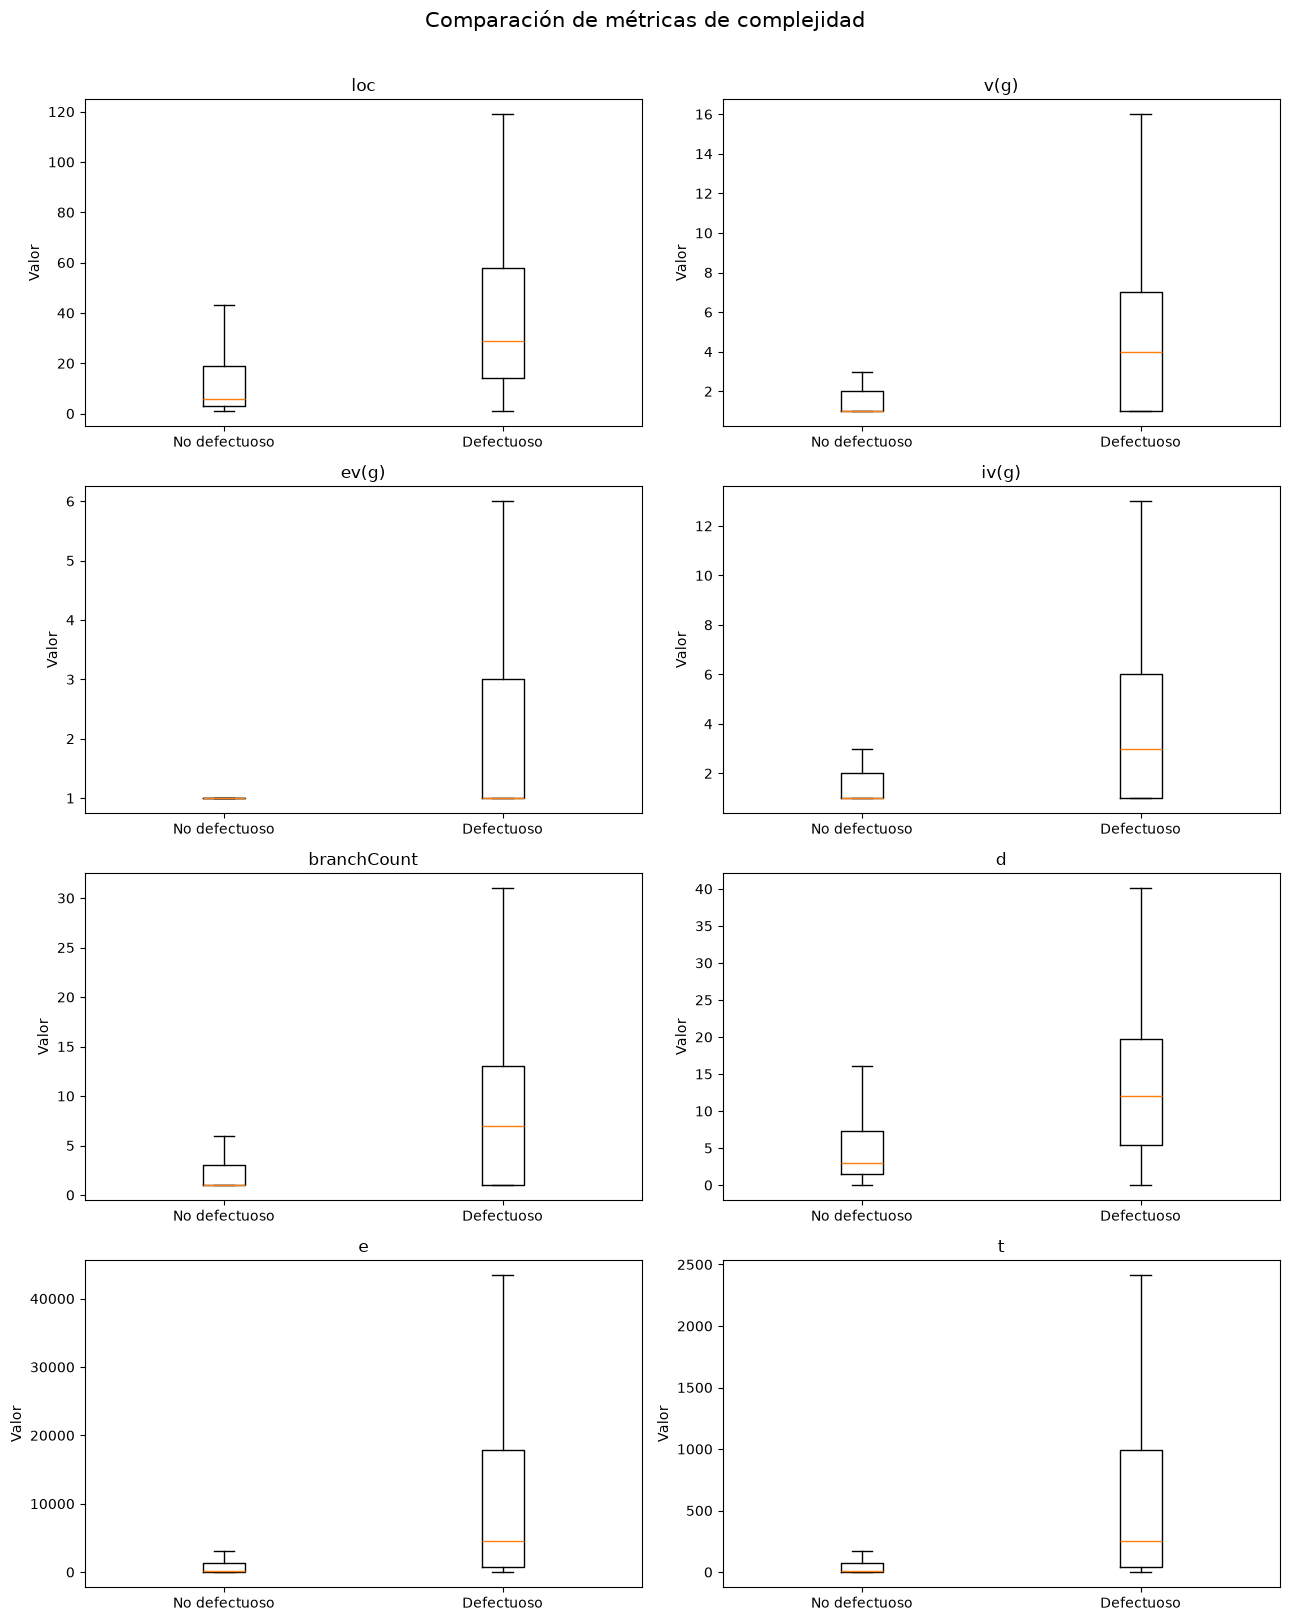

In [102]:
clases = set(df["defects"].dropna().unique())

etiqueta_def = "true" if "true" in clases else sorted(clases)[-1]
etiqueta_no_def = "false" if "false" in clases else sorted(clases)[0]

metricas_complejidad_candidatas = [
    "loc", "v(g)", "ev(g)", "iv(g)", "branchCount", "d", "e","t"
]
metricas_complejidad = [
    m for m in metricas_complejidad_candidatas if m in metricas
]

n_cols = 2
n_rows = int(np.ceil(len(metricas_complejidad) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(13, n_rows * 4))
axes = np.array(axes).reshape(-1)

datos_no_def = df[df["defects"] == etiqueta_no_def]
datos_def = df[df["defects"] == etiqueta_def]

for ax, metrica in zip(axes, metricas_complejidad):
    ax.boxplot(
        [
            datos_no_def[metrica].dropna(),
            datos_def[metrica].dropna()
        ],
        tick_labels=["No defectuoso", "Defectuoso"],
        showfliers=False
    )
    ax.set_title(metrica)
    ax.set_ylabel("Valor")

for ax in axes[len(metricas_complejidad):]:
    ax.axis("off")

fig.suptitle(
    "Comparación de métricas de complejidad",
    fontsize=15,
    y=1.01
)
plt.tight_layout()
plt.show()


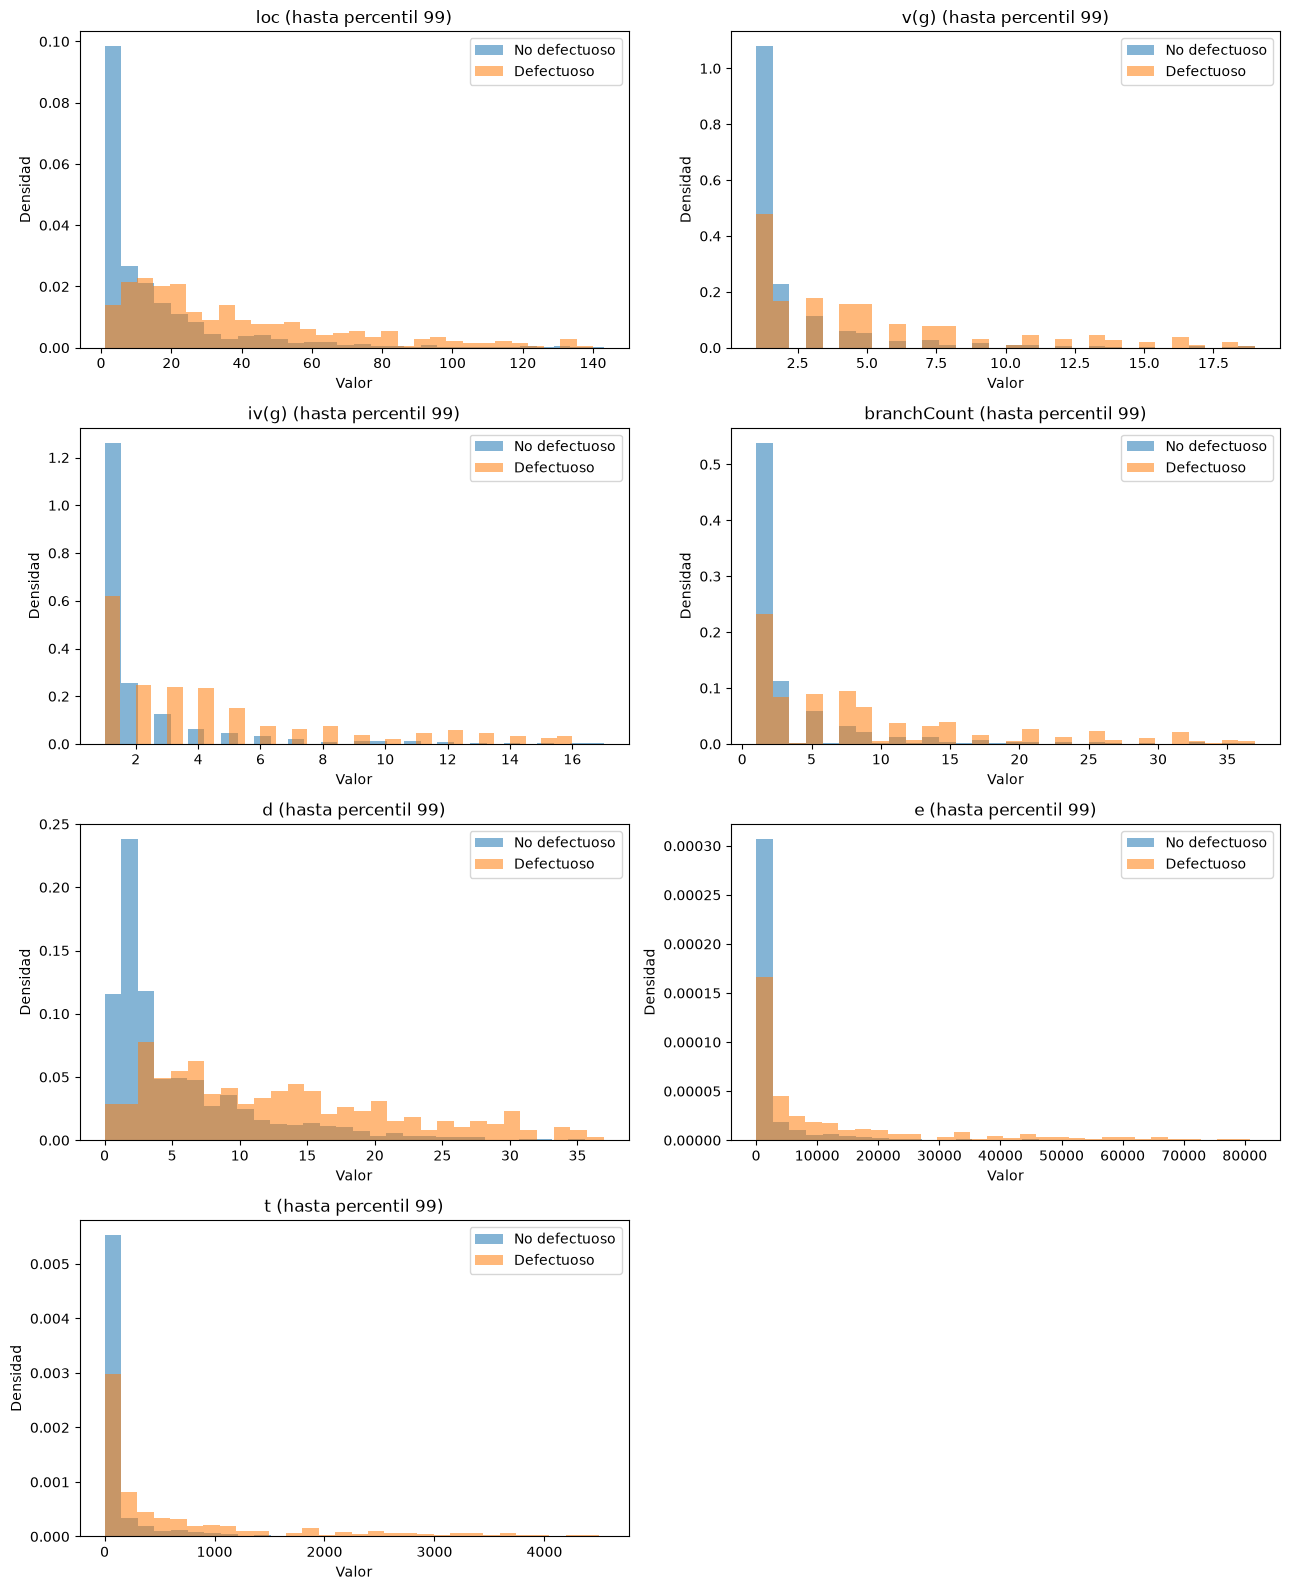

In [103]:
metricas_para_superponer = [
    m for m in ["loc", "v(g)", "iv(g)", "branchCount", "d", "e","t"]
    if m in metricas
]

n_cols = 2
n_rows = int(np.ceil(len(metricas_para_superponer) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(13, n_rows * 4))
axes = np.array(axes).reshape(-1)

for ax, metrica in zip(axes, metricas_para_superponer):
    limite = df[metrica].quantile(0.99)
    ax.hist(
        datos_no_def.loc[datos_no_def[metrica] <= limite, metrica].dropna(),
        bins=30,
        alpha=0.55,
        density=True,
        label="No defectuoso"
    )
    ax.hist(
        datos_def.loc[datos_def[metrica] <= limite, metrica].dropna(),
        bins=30,
        alpha=0.55,
        density=True,
        label="Defectuoso"
    )

    ax.set_title(f"{metrica} (hasta percentil 99)")
    ax.set_xlabel("Valor")
    ax.set_ylabel("Densidad")
    ax.legend()

for ax in axes[len(metricas_para_superponer):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


• Responder a las siguientes preguntas:
1. ¿Qué métrica presenta mayor dispersión? La metrica locCodeAndComment tiene la mayor dispersión tomando en cuenta la dispersión relativa, ya que tiene un oeficiente alto, en caso que solo se considere la desviacion estandar, la metrica e que es el esfuerzo de halstead, presenta la mayor dispersion absoluta con una desviacion estándar de 17,444.98.

2. ¿Qué métrica presenta los valores máximos
más elevados? El esfuerzo de Halstead (e) es el que tiene el valor mas elevado en el conjunto de datos, alcanzando un aprox de 324,804.51, luego esta la t y v.

3. ¿Existen evidencias visuales de que los
módulos defectuosos son más complejos? Si, los diagramas de caja y los histogramas muestran que los módulos defectuosos tienden a presentar valores superiores en varias métricas relacionadas con tamaño y complejidad, por ejemplo: 

- loc
- v(g)
- iv(g)
- branchCount
- d
- e
- t


4. ¿Cuál de las métricas analizadas parece
más prometedora para construir un
predictor? loc (líneas de código) parece mas prometedor para construir un predictor de defectos. Los módulos no defectuosos presentan una mediana de solamente 6 LOC, mientras que los defectuosos alcanzan una mediana de 29 LOC. En las medias también se observa una diferencia considerable: 15.94 frente a 44.61.